In [10]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np

In [11]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [12]:
# 1. 데이터 전처리
length = bream_length + smelt_length
weight = bream_weight + smelt_weight
# data = [[l,w] for l,w in zip(length,weight)] # 방법2
data = np.column_stack((length,weight)) # 방법1 
# data2 = data+2 # 방법 1이 더 용이함
# label = ['1']*35 + ['0']*14
label = ['도미']*35 + ['빙어']*14 # 이렇게도 사용이 가능함
len(length)

49

In [13]:
# 정규화 방법1
# # 정규화 작업
# # 표준점수 = (특성값 - 산술평균) / 표준편차
mean = np.mean(data,axis=0) # 열의 기준으로 산술평균
std = np.std(data,axis=0) # 열의 기준으로 표준편차
train_scaled = (data-mean) / std


In [14]:
# # 정규화 방법2
# # # 정규화작업
# from sklearn.preprocessing import StandardScaler # 정규화해주는 클래스 
# ss = StandardScaler()               # 정규화 선언
# ss.fit(data)                        # 정규화 학습
# train_scaled = ss.transform(data)   # 정규화변환
# trian_data,test_data,train_label,test_label = \
# train_test_split(train_scaled,label)
# train_scaled

In [15]:
# 학습데이타, 테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(train_scaled,label)


In [16]:
# 데이터 학습 ,데이터 예측, 정확도
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data) # 예측되어서 나온값과 실제 정답 비교
score = clf.score(test_data,test_label) # 방법1: 테스트데이터를 가지고 어느정도 정답을 맞췄는지 확인 
# score = metrics.accuracy_score(result,test_label) # 방법1: 예측되어서 나온 값과 실제정답과 비교
score

1.0

In [17]:
# input을 받아서 도미인지, 빙어인지 확인하시오
# 길이, 무게
input1= input('25,120')
input1 = input1.split(',')
input2 = list(map(float,input1))
new_input = (input2-mean)/std
result2 = clf.predict([new_input])
result2
# 성능평가
report = metrics.classification_report(test_label,result)
# ※ 품종별 정밀도·재현율 표. print()로 출력해야 줄바꿈이 보임
report

'              precision    recall  f1-score   support\n\n          도미       1.00      1.00      1.00         8\n          빙어       1.00      1.00      1.00         5\n\n    accuracy                           1.00        13\n   macro avg       1.00      1.00      1.00        13\nweighted avg       1.00      1.00      1.00        13\n'

In [18]:
distances, indexes = clf.kneighbors([new_input]) # 도미로 판단하게된 데이터가 어떤것인지 알려줌.
indexes

array([[20,  5, 35, 18, 32]])

[머신러닝 확인사항]

1. 데이터 전처리 - null처리
2. 정규화 작업
3. 학습데이터, 테스트데이터 분리
4. 데이터학습,테스트예측,정확도
5. 산점도 그래프

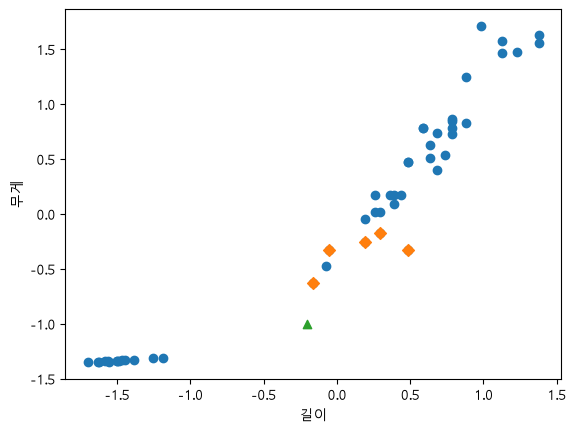

In [19]:
# 그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.scatter(new_input[0],new_input[1],marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()